In [1]:
import os
import struct
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def read_idx_images(filename):
    with open(filename, 'rb') as f:
        magic, num, rows, cols = struct.unpack('>IIII', f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8).reshape(num, rows, cols)
    return images

def read_idx_labels(filename):
    with open(filename, 'rb') as f:
        magic, num = struct.unpack('>II', f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

def load_mnist_data(data_dir='.'):
    candidates = [
        ('train-images.idx3-ubyte', 'train-labels.idx1-ubyte',
         't10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte'),
        ('train-images-idx3-ubyte', 'train-labels-idx1-ubyte',
         't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte')
    ]
    
    for tr_img, tr_lbl, te_img, te_lbl in candidates:
        p_tr_img = os.path.join(data_dir, tr_img)
        p_tr_lbl = os.path.join(data_dir, tr_lbl)
        p_te_img = os.path.join(data_dir, te_img)
        p_te_lbl = os.path.join(data_dir, te_lbl)
        
        if all(os.path.exists(p) for p in [p_tr_img, p_tr_lbl, p_te_img, p_te_lbl]):
            print("Загрузка данных MNIST...")
            X_train_raw = read_idx_images(p_tr_img)
            y_train_raw = read_idx_labels(p_tr_lbl)
            X_test_raw = read_idx_images(p_te_img)
            y_test_raw = read_idx_labels(p_te_lbl)
            return X_train_raw, y_train_raw, X_test_raw, y_test_raw

    print("Загрузка MNIST")
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
    X_all = mnist.data.astype(np.uint8).reshape(-1, 28, 28)
    y_all = mnist.target.astype(np.uint8)
    return X_all[:60000], y_all[:60000], X_all[60000:], y_all[60000:]

X_train_raw, y_train, X_test_raw, y_test = load_mnist_data(data_dir='.')

print("\n=== Информация о наборе данных MNIST ===")
print(f"Количество примеров в обучающей выборке : {X_train_raw.shape[0]}")
print(f"Количество примеров в тестовой выборке  : {X_test_raw.shape[0]}")
print(f"Форма одного изображения (w x h)        : {X_train_raw[0].shape}")
print(f"train / test                            : {y_train.shape} / {y_test.shape}")
print(f"Уникальные классы меток                 : {np.unique(y_train)}")

Загрузка MNIST

=== Информация о наборе данных MNIST ===
Количество примеров в обучающей выборке : 60000
Количество примеров в тестовой выборке  : 10000
Форма одного изображения (w x h)        : (28, 28)
train / test                            : (60000,) / (10000,)
Уникальные классы меток                 : [0 1 2 3 4 5 6 7 8 9]


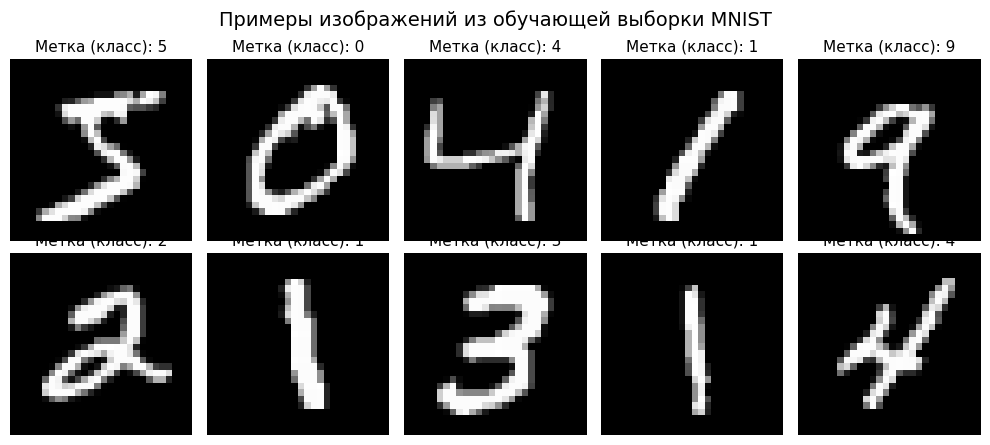

Форма X_train после векторизации : (60000, 784)
Форма одного входа сети          : (784,)
Форма одной One-Hot метки        : (10,) (пример для '5': [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.])


In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
fig.suptitle("Примеры изображений из обучающей выборки MNIST", fontsize=14)

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_raw[i], cmap='gray')
    ax.set_title(f"Метка (класс): {y_train[i]}", fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()

num_features = X_train_raw.shape[1] * X_train_raw.shape[2]
num_classes = 10

X_train = X_train_raw.reshape(-1, num_features).astype(np.float32) / 255.0
X_test = X_test_raw.reshape(-1, num_features).astype(np.float32) / 255.0

def one_hot_encode(labels, num_classes=10):
    one_hot = np.zeros((labels.shape[0], num_classes), dtype=np.float32)
    one_hot[np.arange(labels.shape[0]), labels] = 1.0
    return one_hot

Y_train_oh = one_hot_encode(y_train, num_classes)
Y_test_oh = one_hot_encode(y_test, num_classes)

print(f"Форма X_train после векторизации : {X_train.shape}")
print(f"Форма одного входа сети          : {X_train[0].shape}")
print(f"Форма одной One-Hot метки        : {Y_train_oh[0].shape} (пример для '{y_train[0]}': {Y_train_oh[0]})")

In [3]:
class TwoLayerNet:
    def __init__(self, input_size=784, hidden_size=300, output_size=10):
        self.W1 = np.random.randn(input_size, hidden_size).astype(np.float32) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size), dtype=np.float32)
        
        self.W2 = np.random.randn(hidden_size, output_size).astype(np.float32) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size), dtype=np.float32)

    @staticmethod
    def relu(z):
        return np.maximum(0.0, z)

    @staticmethod
    def softmax(z):
        shifted_z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(shifted_z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    @staticmethod
    def cross_entropy_loss(y_pred, y_true_oh):
        eps = 1e-12
        y_pred_clipped = np.clip(y_pred, eps, 1.0 - eps)
        loss = -np.sum(y_true_oh * np.log(y_pred_clipped)) / y_true_oh.shape[0]
        return float(loss)

    def forward(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = self.relu(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = self.softmax(self.Z2)
        return self.A2

    def backward_and_update(self, Y_batch_oh, learning_rate):
        batch_size = Y_batch_oh.shape[0]
        dZ2 = (self.A2 - Y_batch_oh) / batch_size                 
        dW2 = self.A1.T @ dZ2                                      
        db2 = np.sum(dZ2, axis=0, keepdims=True)                  
        dA1 = dZ2 @ self.W2.T                                     
        dZ1 = dA1 * (self.Z1 > 0)                                 
        dW1 = self.X.T @ dZ1                                      
        db1 = np.sum(dZ1, axis=0, keepdims=True)                   
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2

    def evaluate(self, X, y_true_labels, Y_true_oh):
        probs = self.forward(X)
        loss = self.cross_entropy_loss(probs, Y_true_oh)
        preds = np.argmax(probs, axis=1)
        accuracy = np.mean(preds == y_true_labels) * 100.0
        classification_error = 100.0 - accuracy
        return loss, classification_error, accuracy

In [ ]:
HIDDEN_NEURONS = 300  
LEARNING_RATE = 0.1   
BATCH_SIZE = 32         
EPOCHS = 20            

model = TwoLayerNet(
    input_size=num_features,
    hidden_size=HIDDEN_NEURONS,
    output_size=num_classes
)

num_train = X_train.shape[0]
history = {'loss': [], 'err': [], 'acc': [], 'time': []}

print("=== Начало обучения нейронной сети ===")
print(f"Параметры: s={HIDDEN_NEURONS}, lr={LEARNING_RATE}, batch_size={BATCH_SIZE}, epochs={EPOCHS}\n")

total_start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start_time = time.time()

    indices = np.random.permutation(num_train)
    X_train_shuffled = X_train[indices]
    Y_train_shuffled = Y_train_oh[indices]

    for start_idx in range(0, num_train, BATCH_SIZE):
        end_idx = start_idx + BATCH_SIZE
        X_batch = X_train_shuffled[start_idx:end_idx]
        Y_batch = Y_train_shuffled[start_idx:end_idx]

        model.forward(X_batch)
        model.backward_and_update(Y_batch, LEARNING_RATE)

    train_loss, train_err, train_acc = model.evaluate(X_train, y_train, Y_train_oh)
    epoch_time = time.time() - epoch_start_time

    history['loss'].append(train_loss)
    history['err'].append(train_err)
    history['acc'].append(train_acc)
    history['time'].append(epoch_time)

    print(
        f"Эпоха {epoch:2d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Ошибка классификации: {train_err:5.2f}% (Точность: {train_acc:6.2f}%) | "
        f"Время: {epoch_time:.2f} с"
    )

total_time = time.time() - total_start_time
print(f"\nОбучение завершено за {total_time:.2f} с.")

test_loss, test_err, test_acc = model.evaluate(X_test, y_test, Y_test_oh)

print("\n=== Результаты на тестовом наборе данных (10 000 примеров) ===")
print(f"Значение функции ошибки : {test_loss:.4f}")
print(f"Ошибка классификации на тесте: {test_err:.2f}%")
print(f"Точность классификации на тесте: {test_acc:.2f}%")

=== Начало обучения нейронной сети ===
Параметры: s=300, lr=0.1, batch_size=32, epochs=20

Эпоха  1/20 | Train Loss: 0.1621 | Ошибка классификации:  4.55% (Точность:  95.45%) | Время: 1.81 с
Эпоха  2/20 | Train Loss: 0.0998 | Ошибка классификации:  2.78% (Точность:  97.22%) | Время: 1.98 с
Эпоха  3/20 | Train Loss: 0.0734 | Ошибка классификации:  2.03% (Точность:  97.97%) | Время: 1.85 с
Эпоха  4/20 | Train Loss: 0.0543 | Ошибка классификации:  1.43% (Точность:  98.57%) | Время: 2.07 с
Эпоха  5/20 | Train Loss: 0.0518 | Ошибка классификации:  1.43% (Точность:  98.57%) | Время: 1.85 с
Эпоха  6/20 | Train Loss: 0.0377 | Ошибка классификации:  0.95% (Точность:  99.05%) | Время: 1.84 с
Эпоха  7/20 | Train Loss: 0.0324 | Ошибка классификации:  0.79% (Точность:  99.21%) | Время: 1.90 с
Эпоха  8/20 | Train Loss: 0.0261 | Ошибка классификации:  0.59% (Точность:  99.41%) | Время: 1.91 с
Эпоха  9/20 | Train Loss: 0.0219 | Ошибка классификации:  0.47% (Точность:  99.53%) | Время: 1.87 с
Эпоха 10/